#### Objective -
##### Build a model which will predict the profit that starting company can have when administration amount,R & D Spend amount,Marketing amount the state of the oraganization is specified.

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [60]:
df = pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/50_Startups.csv")
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.1 KB


In [62]:
df.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [63]:
df.isnull().sum()

R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

In [64]:
df.duplicated().sum()

np.int64(0)

In [65]:
df.nunique()

R&D Spend          49
Administration     50
Marketing Spend    48
State               3
Profit             50
dtype: int64

In [66]:
df.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='str')

{'whiskers': [<matplotlib.lines.Line2D at 0x1a922afb390>,
 'caps': [<matplotlib.lines.Line2D at 0x1a922afb610>,
 'boxes': [<matplotlib.lines.Line2D at 0x1a922af8910>],
 'medians': [<matplotlib.lines.Line2D at 0x1a922afb890>],
 'fliers': [<matplotlib.lines.Line2D at 0x1a922afb9d0>],
 'means': []}

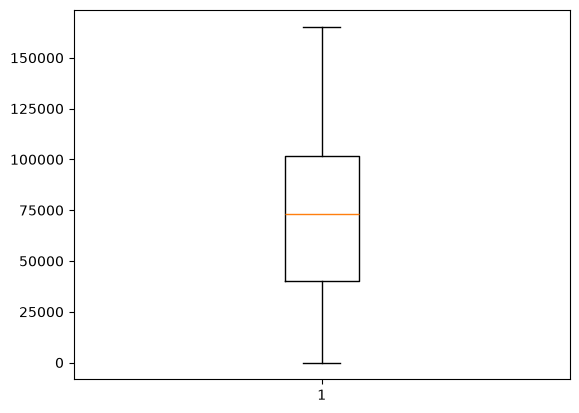

In [67]:
plt.boxplot(df['R&D Spend'])

{'whiskers': [<matplotlib.lines.Line2D at 0x1a923436c10>,
 'caps': [<matplotlib.lines.Line2D at 0x1a923436e90>,
 'boxes': [<matplotlib.lines.Line2D at 0x1a923436ad0>],
 'medians': [<matplotlib.lines.Line2D at 0x1a923437110>],
 'fliers': [<matplotlib.lines.Line2D at 0x1a923437250>],
 'means': []}

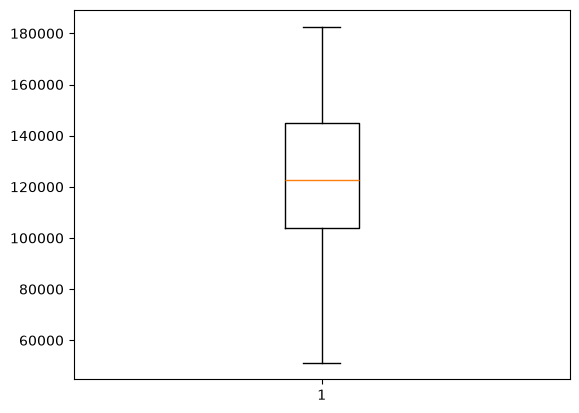

In [68]:
plt.boxplot(df['Administration'])

{'whiskers': [<matplotlib.lines.Line2D at 0x1a92347e490>,
 'caps': [<matplotlib.lines.Line2D at 0x1a92347e710>,
 'boxes': [<matplotlib.lines.Line2D at 0x1a92347e350>],
 'medians': [<matplotlib.lines.Line2D at 0x1a92347e990>],
 'fliers': [<matplotlib.lines.Line2D at 0x1a92347ead0>],
 'means': []}

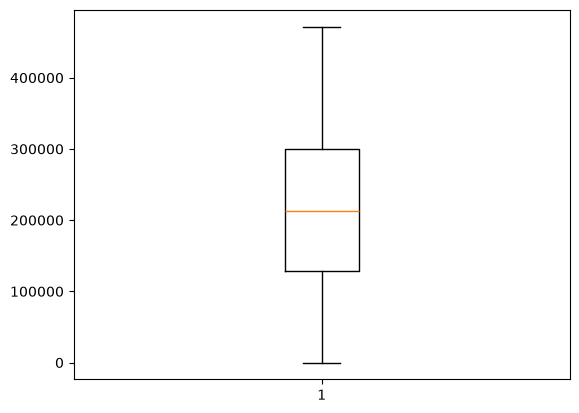

In [69]:
plt.boxplot(df['Marketing Spend'])

In [70]:
df['State'].unique()

<StringArray>
['New York', 'California', 'Florida']
Length: 3, dtype: str

In [71]:
data = pd.get_dummies(df, dtype=int)
data.head()

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,0,1
1,162597.70,151377.59,443898.53,191792.06,1,0,0
2,153441.51,101145.55,407934.54,191050.39,0,1,0
3,144372.41,118671.85,383199.62,182901.99,0,0,1
4,142107.34,91391.77,366168.42,166187.94,0,1,0


In [72]:
data.describe()

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200,0.340000,0.320000,0.340000
std,45902.256482,28017.802755,122290.310726,40306.180338,0.478518,0.471212,0.478518
min,0.000000,51283.140000,0.000000,14681.400000,0.000000,0.000000,0.000000
25%,39936.370000,103730.875000,129300.132500,90138.902500,0.000000,0.000000,0.000000
50%,73051.080000,122699.795000,212716.240000,107978.190000,0.000000,0.000000,0.000000
75%,101602.800000,144842.180000,299469.085000,139765.977500,1.000000,1.000000,1.000000
max,165349.200000,182645.560000,471784.100000,192261.830000,1.000000,1.000000,1.000000


In [73]:
###Scaling

In [74]:
X = data.drop(['Profit'], axis=1)
y = data['Profit']

In [75]:
from sklearn.model_selection import train_test_split

In [76]:
X_train,X_test,y_train,y_test = train_test_split(X,y, random_state = 40,test_size=0.2)

In [77]:
X_train.shape

(40, 6)

In [78]:
X_test.shape

(10, 6)

In [79]:
y_train.shape

(40,)

In [80]:
y_test.shape

(10,)

In [81]:
from sklearn.linear_model import LinearRegression

In [82]:
regressor = LinearRegression()

In [83]:
regressor.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 0.79, 0. , 0.03, 1615.04, 375.81,-1990.85]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['R&D Spend','Administration','Marketing Spend','State_California', 'State_Florida','State_New York']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.779e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [84]:
test_pred = regressor.predict(X_test)

In [85]:
from sklearn.metrics import r2_score, root_mean_squared_error

In [86]:
r2_score(y_test, test_pred)

0.929766247134056

In [87]:
root_mean_squared_error(y_test, test_pred)

14390.131860302754

In [88]:
adm = float(input('Enter administration cost:'))
rad = float(input('Enter R&D cost:'))
mark = float(input('Enter Marketing Cost:'))
cl, fl, ny = 0, 0, 0
state = input('Enter State:')
if(state == 'California'):
    cl = 1
elif(state == "New York"):
    ny = 1
else:
    fl = 1

Enter administration cost: 10000
Enter R&D cost: 40000
Enter Marketing Cost: 70000
Enter State: California


In [91]:
cl, fl, ny

(1, 0, 0)

In [90]:
regressor.predict([[rad, adm, mark, cl, fl, ny]])

C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([82887.0100959])